# Notebook for proposal plots HFORT 2021

MiSoLFA/PADRE and SoLO plots 

Requires:
* `solar_cycle24_flares.csv` which is a file of solar flares > C1 GOES class of solar cycle
* `date_SES_ESS.csv` ephemeris solar orbiter angles
* `sim_struct.sav` simulated anisotropy data

This estimates total number of flares observed by both SoLO STIX and MiSolFA. 


In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib import dates
from sunpy.net import Fido
from sunpy.net import attrs as a
import sunpy.sun as sun
from sunpy.time import parse_time
from sunpy.time import TimeRange
import sunpy.timeseries as ts
from dateutil.relativedelta import relativedelta
from astropy import units as u
import seaborn as sns
from scipy.io import readsav
from scipy.interpolate import interp2d
import warnings
from astropy.time import Time, TimeDelta
warnings.filterwarnings("ignore")

sns.set(rc={"figure.dpi":100, 'savefig.dpi':100})
sns.set_style("whitegrid")

First get flares from past solar cycle. This is now saved in `solar_cycle24_flares.csv` so this can just be read in instead of needing to call function.

In [2]:
def get_flares():
    """
    Query HEK for flares > C1 from past solar cycle and save results to csv.
    
    """
    event_type = "FL"
    tstart = "2009/01/01"
    tend = "2019/12/31"
    result = Fido.search(a.Time(tstart, tend),
                         a.hek.EventType(event_type),
                         a.hek.OBS.Observatory == "GOES", 
                         a.hek.FL.GOESCls >= "C1.0")
    
    new_table = result["hek"]["event_starttime", "event_peaktime",
                             "event_endtime", "fl_goescls", "ar_noaanum"]
    new_table.write("solar_cycle24_flares.csv", format="csv")

## Define start and end of MiSoLFA/Padre
These can be changed, bit of a guesstimation assuming launch in May 2024. Original proposal had proposed launch date of May 2023.

In [3]:
misolfa_start = parse_time("2025-06-01").datetime
misolfa_end = misolfa_start + relativedelta(years=1)

## Using data of flare frequency from past solar cycle

To determine estimated number of flares SoLO and MiSolFA/Padre will see

In [4]:
flares_24 = pd.read_csv("solar_cycle24_flares.csv")

Make column called `goes_cls` which just contains if C, X or M

In [5]:
def get_class(goes_cls):
    return goes_cls[0]

flares_24["goes_cls"] = flares_24["fl_goescls"].map(get_class)

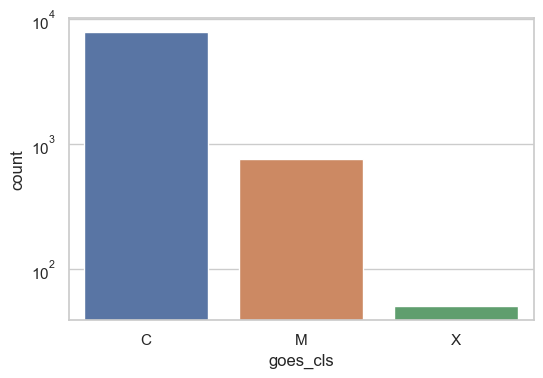

In [6]:
sns.countplot(flares_24["goes_cls"])
plt.yscale("log")

Map the times to 11 in future (i.e. next solar cycle), and set index to those times

In [7]:
times = parse_time(flares_24["event_starttime"]).datetime
flares_24["new_times"] = times + relativedelta(years=11)
flares_24 = flares_24.set_index("new_times")

Get monthly flares and count numbers per month

In [8]:
flares_24["counts"] = np.ones(len(flares_24))
flares_24_c = flares_24[flares_24["goes_cls"]=="C"].resample("1M").sum()
flares_24_m = flares_24[flares_24["goes_cls"]=="M"].resample("1M").sum()
flares_24_x = flares_24[flares_24["goes_cls"]=="X"].resample("1M").sum()

<AxesSubplot:xlabel='new_times'>

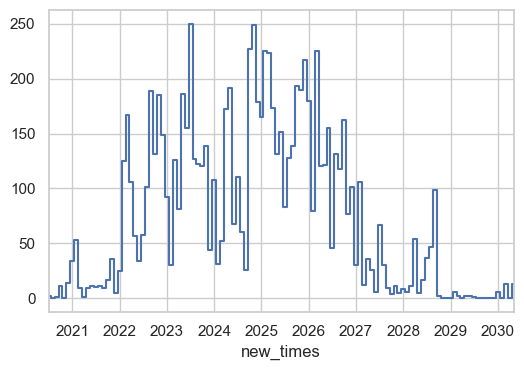

In [9]:
flares_24.resample("1M").sum()["counts"].plot(drawstyle="steps-mid")

In [10]:
time_range = TimeRange("2008-06-01 00:00", Time.now())
result = Fido.search(a.Time(time_range), a.Instrument('noaa-indices'))
f_noaa_indices = Fido.fetch(result)
result = Fido.search(a.Time(time_range.end, time_range.end + TimeDelta(4 * u.year)),
                     a.Instrument('noaa-predict'))
print(result)
f_noaa_predict = Fido.fetch(result)
noaa = ts.TimeSeries(f_noaa_indices, source='noaaindices').truncate(time_range)
noaa_predict = ts.TimeSeries(f_noaa_predict, source='noaapredictindices')

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

SSL error in data received
protocol: <asyncio.sslproto.SSLProtocol object at 0x7fd958b76860>
transport: <_SelectorSocketTransport fd=77 read=polling write=<idle, bufsize=0>>
Traceback (most recent call last):
  File "/Users/sdchris1/anaconda3/lib/python3.7/asyncio/sslproto.py", line 526, in data_received
    ssldata, appdata = self._sslpipe.feed_ssldata(data)
  File "/Users/sdchris1/anaconda3/lib/python3.7/asyncio/sslproto.py", line 207, in feed_ssldata
    self._sslobj.unwrap()
  File "/Users/sdchris1/anaconda3/lib/python3.7/ssl.py", line 767, in unwrap
    return self._sslobj.shutdown()
ssl.SSLError: [SSL: KRB5_S_INIT] application data after close notify (_ssl.c:2609)


Results from 1 Provider:

1 Results from the NOAAPredictClient:
 Instrument     Physobs     Source Provider
------------ -------------- ------ --------
NOAA-Predict sunspot number   ISES     SWPC




Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

SSL error in data received
protocol: <asyncio.sslproto.SSLProtocol object at 0x7fd958beaf98>
transport: <_SelectorSocketTransport fd=83 read=polling write=<idle, bufsize=0>>
Traceback (most recent call last):
  File "/Users/sdchris1/anaconda3/lib/python3.7/asyncio/sslproto.py", line 526, in data_received
    ssldata, appdata = self._sslpipe.feed_ssldata(data)
  File "/Users/sdchris1/anaconda3/lib/python3.7/asyncio/sslproto.py", line 207, in feed_ssldata
    self._sslobj.unwrap()
  File "/Users/sdchris1/anaconda3/lib/python3.7/ssl.py", line 767, in unwrap
    return self._sslobj.shutdown()
ssl.SSLError: [SSL: KRB5_S_INIT] application data after close notify (_ssl.c:2609)


In [11]:
noaa_predict

Plot the number of flares `predicted` for the next solar cycle (i.e. same as cycle 24), with the launch of MiSolFA/Padre and SoLO also marked.

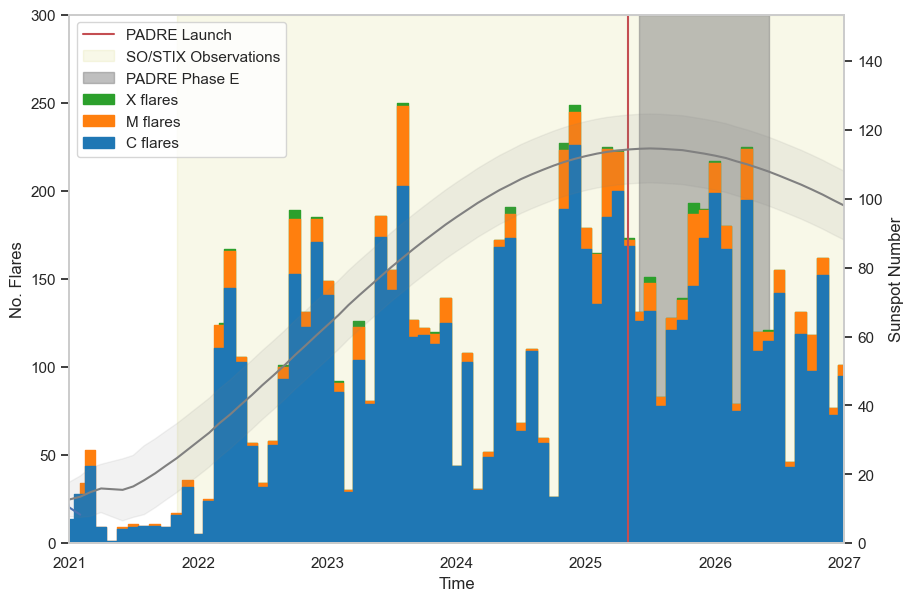

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))


ax.axvspan(dates.date2num(parse_time("2021-11-01").datetime), 
           dates.date2num(parse_time("2027-01-01").datetime), 
           alpha=0.1, label="SO/STIX Observations", color="tab:olive", zorder=0)

ax.axvline(misolfa_start - relativedelta(months=1), color="r", 
           label="PADRE Launch")

ax.axvspan(dates.date2num(misolfa_start), 
           dates.date2num(misolfa_end), 
           color="grey", alpha=0.5, zorder=0, 
           label="PADRE Phase E")

ax2 = ax.twinx()
ax2.plot(noaa.index, noaa.quantity('sunspot RI'), label='Sunspot Number')
ax2.plot(noaa_predict.index, noaa_predict.quantity('sunspot'),
        color='grey', label='Near-term Prediction')
ax2.fill_between(noaa_predict.index, noaa_predict.quantity('sunspot low'),
                noaa_predict.quantity('sunspot high'), alpha=0.1, color='grey')
ax2.set_ylabel("Sunspot Number")
ax2.set_ylim(0)

ax.fill_between(flares_24_c.index, flares_24_c["counts"]+flares_24_m["counts"]+flares_24_x["counts"], 
                step="mid", 
                color="tab:green", 
                label="X flares")

ax.fill_between(flares_24_c.index, flares_24_c["counts"]+flares_24_m["counts"], 
                step="mid", 
                color="tab:orange", 
                label="M flares")

ax.fill_between(flares_24_c.index, flares_24_c["counts"], 
                step="mid", 
                color="tab:blue", 
                label="C flares")
ax.grid(False)
ax2.grid(False)

ax.set_xlim(parse_time("2021-01-01").datetime, parse_time("2027-01-01").datetime)
ax.set_ylim(0, 300)
ax.xaxis.set_minor_locator(dates.MonthLocator(interval=2))
ax.legend(loc="upper left")

ax.set_xlabel("Time")
ax.set_ylabel("No. Flares")

plt.savefig('fig6_solar_cycle.pdf')
plt.show()

In [44]:
misolfa_flares = flares_24.truncate(misolfa_start, misolfa_end)

In [45]:
no_x_class_flares = np.sum(misolfa_flares["goes_cls"].isin(["X"]))
no_m_class_flares = np.sum(misolfa_flares["goes_cls"].isin(["M"]))
no_c_class_flares = np.sum(misolfa_flares["goes_cls"].isin(["C"]))


print("The number of X-class flares during misolfa year is {:d}" \
      .format(no_x_class_flares))

print("The number of M-class flares during misolfa year is {:d}" \
      .format(no_m_class_flares))

print("The number of C-class flares during misolfa year is {:d}" \
      .format(no_c_class_flares))

The number of X-class flares during misolfa year is 16
The number of M-class flares during misolfa year is 178
The number of C-class flares during misolfa year is 1702


(Note - whats written in the proposal is ~7 X-class flares and >100 M-class flares, I'm not entirely sure where 7 came from as when I put in the launch of 2023-05-01 it doesn't give 7 - but doesnt really matter)

### Number of flares by both (conservative)
Following the logic from whats written in the proposal : MiSolFA should observe ~ half of these. If STIX also has a duty cycle of 50% then ~25% of flares will be observed by both. 

In [46]:
print("The number of X-class observed by both STIX and MiSoFA is ~ {:d}".format(round(no_x_class_flares*0.25)))
print("The number of M-class observed by both STIX and MiSoFA is ~ {:d}".format(round(no_m_class_flares*0.25)))

The number of X-class observed by both STIX and MiSoFA is ~ 4
The number of M-class observed by both STIX and MiSoFA is ~ 44


## Positions and seperation of SoLO and MiSolFA.

Read in the data and plot

In [19]:
position_data = pd.read_csv('date_SES_ESS.csv', parse_dates=True, 
                            index_col=1, 
                            names=['num', 'Sun-Earth-SO-rad', 'Earth-Sun-SO-rad'])

position_data['deg'] = np.rad2deg(position_data['Earth-Sun-SO-rad'])

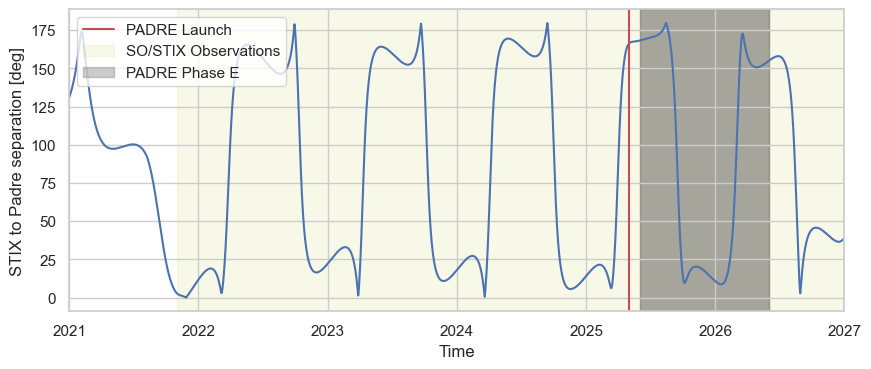

In [23]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(position_data.index, position_data['deg'])
ax.axvspan(misolfa_start, misolfa_end, alpha=0.5, color='grey', zorder=0)
ax.set_xlim(parse_time("2021-01-01").datetime, parse_time("2027-01-01").datetime)

ax.axvspan(dates.date2num(parse_time("2021-11-01").datetime), 
           dates.date2num(parse_time("2027-01-01").datetime), 
           alpha=0.1, label="SO/STIX Observations", color="tab:olive", zorder=0)

ax.axvline(misolfa_start - relativedelta(months=1), color="r", 
           label="PADRE Launch")

ax.axvspan(dates.date2num(misolfa_start), 
           dates.date2num(misolfa_end), 
           color="grey", alpha=0.4, zorder=0, 
           label="PADRE Phase E")

ax.legend(loc="upper left")

ax.xaxis.set_minor_locator(dates.MonthLocator(interval=2))
ax.set_ylabel('STIX to Padre separation [deg]')
ax.set_xlabel("Time")
plt.savefig("angular_separation.pdf")
plt.show()

(0.0, 90.0)

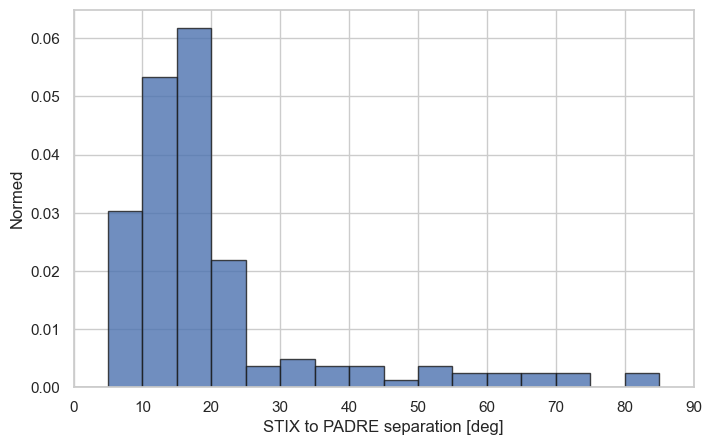

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(position_data['deg'][misolfa_start:misolfa_end], 
        bins=np.arange(0, 90, 5), 
        density=True,
        alpha=0.8, 
        edgecolor="k")
ax.set_xlabel('STIX to PADRE separation [deg]')
ax.set_ylabel("Normed")
ax.set_xlim(0, 90)


## MCMC test for number of flares

In [26]:
rsun_arcsec = sun.physical_constants['average angular size']

num_flares = 10000000

random_lat = np.random.random(num_flares) * 60 * u.deg - 30 * u.deg
random_longitude = np.random.random(num_flares)*180-90

In [27]:
solar_orbiter_angles = position_data['deg'][misolfa_start:misolfa_end]

In [28]:
rand_inds = np.random.randint(0, len(solar_orbiter_angles), num_flares)
random_so_hg_lon = solar_orbiter_angles.values[rand_inds] * u.deg
random_misolfa_hg_lon = np.random.random(num_flares) * 180 * u.deg - 90 * u.deg

In [29]:
flare_misolfa_angle = random_misolfa_hg_lon
flare_so_angle = random_misolfa_hg_lon - random_so_hg_lon

### No. flares observed by both (viewing angles between 0 and 90 degrees)

In [30]:
total_flares_observed_both = np.sum(np.abs(flare_so_angle.value) < 90)
print("Total % random flares observed by both is {:.2f}".format(100*(total_flares_observed_both/num_flares)))

Total % random flares observed by both is 46.51


Text(0.5, 0, '| cos(θS) - cos(θM) |')

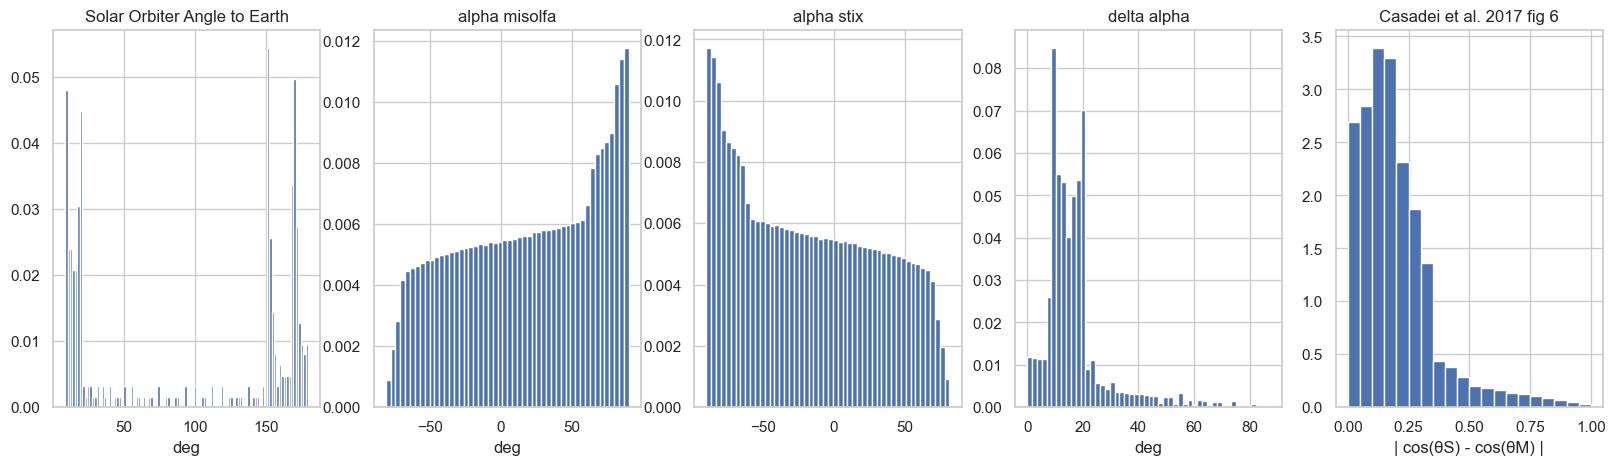

In [31]:
nbins = 50

result = pd.DataFrame({'alpha_mi': flare_misolfa_angle, 'alpha_so': flare_so_angle})
fig, ax = plt.subplots(nrows=1, ncols=5, figsize=(20, 5))

ax[0].hist(solar_orbiter_angles, bins=100, density=True)
ax[0].set_title('Solar Orbiter Angle to Earth')
ax[0].set_xlabel('deg')

# must be observable by both Mi and SO
con1 = np.abs(result['alpha_mi'].values) < 90.0
con2 = np.abs(result['alpha_so'].values) < 90.0

alpha_mi = result['alpha_mi'][con1 * con2].values
alpha_so = result['alpha_so'][con1 * con2].values

ax[1].hist(alpha_mi, bins=nbins, density=True)
ax[1].set_title('alpha misolfa')
ax[1].set_xlabel('deg')

ax[2].hist(alpha_so, bins=nbins, density=True)
ax[2].set_title('alpha stix')

diff = np.abs(np.abs(alpha_so) - np.abs(alpha_mi))
ax[3].hist(diff, bins=nbins, density=True)
ax[3].set_title('delta alpha')
ax[3].set_xlabel('deg')

viewing_angles = np.cos(alpha_so * u.deg).value - np.cos(alpha_mi * u.deg).value
ax[4].hist(np.abs(viewing_angles), bins=20, density=True)
ax[4].set_title('Casadei et al. 2017 fig 6')
ax[4].set_xlabel('| cos(θS) - cos(θM) |')

Text(0, 0.5, 'alpha_so')

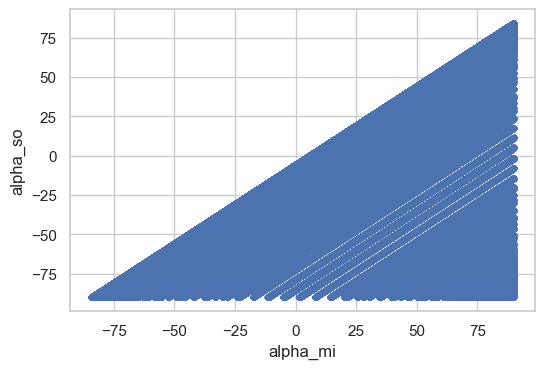

In [56]:
fig, ax = plt.subplots()
ax.plot(result['alpha_mi'][con1 * con2].values, result['alpha_so'][con1 * con2].values, '.')
ax.set_xlabel('alpha_mi')
ax.set_ylabel('alpha_so')

Text(0, 0.5, 'Z')

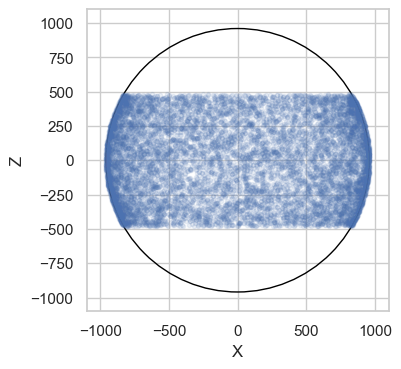

In [57]:
x = (rsun_arcsec) * np.cos(random_lat) * np.cos(random_longitude)
y = (rsun_arcsec) * np.cos(random_lat) * np.sin(random_longitude)
z = (rsun_arcsec) * np.sin(random_lat)
r = np.sqrt(x **2 + z **2)

fig, ax = plt.subplots()
ax.plot(x[0:10000], z[0:10000], '.', alpha=0.1)
circle2 = plt.Circle(xy=(0,0), radius=rsun_arcsec.value, facecolor='none', edgecolor='black')
ax.add_artist(circle2)
ax.set_xlim(-1100, 1100)
ax.set_ylim(-1100, 1100)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel("X")
ax.set_ylabel("Z")

## Anisotropy simulated data

Within the simulated anisotropy file `sim_struct.sav` there are 5 different viewing angle separations, with 3 different "levels" of anisotropy (i.e. larger the number is highly anisotropic, or more beamed). There is simulated data for both the flux comparisons with and without the effects of albedo included.

In [58]:
data_anisotropy = readsav('sim_struct.sav')["sim_struct"]
data_anisotropy.dtype.names

('ANISOTROPY', 'ENERGY', 'VIEW_ANGLE', 'PHOTON_FLUX', 'PHOTON_FLUX_ALB')

In [59]:
(data_anisotropy['view_angle'][0] * u.rad).to('deg')

<Quantity [ 0.      , 20.000002, 40.000004, 60.000004, 80.00001 ] deg>

In [60]:
data_anisotropy["anisotropy"]

array([array([ 0.03,  0.5 , 10.  ], dtype=float32)], dtype=object)

In [61]:
print("shape of energy is ", data_anisotropy["energy"][0].shape)
print("shape of view_angle is ", data_anisotropy["view_angle"][0].shape)
print("shape of photon_flux is", data_anisotropy["photon_flux"][0].shape)
print("shape of photon_flux_alb is", data_anisotropy["photon_flux_alb"][0].shape)
print("shape of anisotropy is", data_anisotropy["anisotropy"][0].shape)

shape of energy is  (20,)
shape of view_angle is  (5,)
shape of photon_flux is (5, 20, 3)
shape of photon_flux_alb is (5, 20, 3)
shape of anisotropy is (3,)


Name some of the variables for ease

In [62]:
energy = data_anisotropy["energy"][0]
view_angles = (data_anisotropy['view_angle'][0] * u.rad).to('deg').value
anisotropy = data_anisotropy["anisotropy"][0]

Plot the directivity for viewing angle = 80 degrees (i.e. data_anisotropy["view_angle"][0][4])

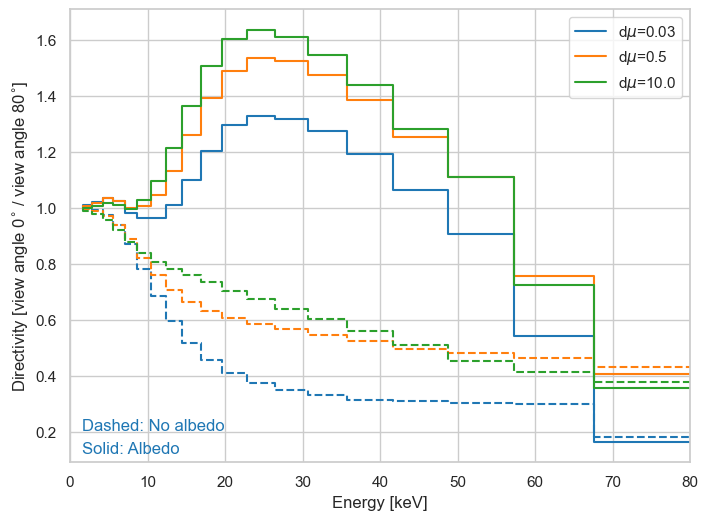

In [63]:
fig, ax = plt.subplots(figsize=(8, 6))
c = ["tab:blue", "tab:orange", "tab:green"]
for i in range(3):
    directivity_alb = data_anisotropy['photon_flux_alb'][0][0, :, i] / data_anisotropy['photon_flux_alb'][0][4, :, i]
    directivity_noalb = data_anisotropy['photon_flux'][0][0, :, i] / data_anisotropy['photon_flux'][0][4, :, i]
    ax.step(energy, directivity_alb, color=c[i], label="d$\mu$="+str(round(anisotropy[i], 2)))
    ax.step(energy, directivity_noalb, linestyle="--", color=c[i])
ax.set_xlabel('Energy [keV]')
ax.set_ylabel('Directivity [view angle 0$^{\circ}$ / view angle 80$^{\circ}$]')
ax.set_xlim(0, 80)
ax.text(0.02, 0.02, "Solid: Albedo", transform=ax.transAxes, color="tab:blue")
ax.text(0.02, 0.07, "Dashed: No albedo", transform=ax.transAxes, color="tab:blue")
ax.legend()

In [64]:
alpha_mi = np.abs(alpha_mi)
alpha_so = np.abs(alpha_so)

def plot_anisotropy_flares(anisotropy_index=0, no_flares=17, m=1000):
    """
    Plot the anisotropy for randomly chosen angles of alpha_mi (misolfa) and 
    alpha_so (solar orbiter). 
    
    Parameters
    ----------
    anisotropy_index : `int` 
        0, 1, or 2 corresponding to 0.03, 0.5, 10
    no_flares : `int`
        the number of flares to scale by (i.e. the expected number of flares to be observed by both)
    m : `int`
        number of random indices to generate 
        
    Returns
    -------
    Average anisotropy between 20 and 30keV (array of length m).
    
    Plots the directivity as function of energy and the number of flares that observed that directivity.
    """
    photon_flux_alb = np.log10(data_anisotropy['photon_flux_alb'][0][:,:,anisotropy_index])
    f = interp2d(view_angles, energy, photon_flux_alb.transpose(), kind='cubic')
    
    m = 1000
    inds = np.random.randint(0, len(alpha_mi), m)

    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

    ax[0].set_xlabel('Energy [keV]')
    ax[0].set_title(f'd$\mu$={data_anisotropy["anisotropy"][0][anisotropy_index]:0.02f}')
    ax[0].set_ylabel('Directivity [view angle 1 / view angle 2]')
    ax[0].set_xlim(0, 60)
    ax[0].set_ylim(0.5, 2)

    avg_ani0 = []
    for this_mi, this_so in zip(alpha_mi[inds], alpha_so[inds]):
        ratio = 10**f(this_mi, energy) / 10**f(this_so, energy)
        if np.average(ratio[10:14]) < 1.0:
            ratio = 1 / ratio
        avg_ani0.append(np.average(ratio[10:14]))
        ax[0].step(energy, ratio, alpha=0.5, color='grey', linewidth=0.1)

    weights = np.ones_like(avg_ani0)/float(len(avg_ani0))
    hist, bins = np.histogram(avg_ani0, bins=np.arange(1, 2, 0.1))

    width = 1.0 * (bins[1] - bins[0])
    center = (bins[:-1] + bins[1:]) / 2 - 0.05

    label = f'>={bins[1]:0.2f} N={no_flares * np.sum(hist[1:] / len(avg_ani0)):0.0f}' \
    + f'\n>={bins[2]:0.2f} N={34/2. * np.sum(hist[2:] / len(avg_ani0)):0.0f}' 
    ax[1].bar(center, no_flares * hist / len(avg_ani0), align='center', width=width, label=label)
    ax[1].set_title(f'd$\mu$={data_anisotropy["anisotropy"][0][anisotropy_index]:0.02f}')
    ax[1].set_ylabel('Number of flares (assuming {:d} total flares)'.format(no_flares))
    ax[1].set_xlabel('Average Directivity [view angle 1 / view angle 2] 20 to 30 keV')
    ax[1].legend()
    return avg_ani0

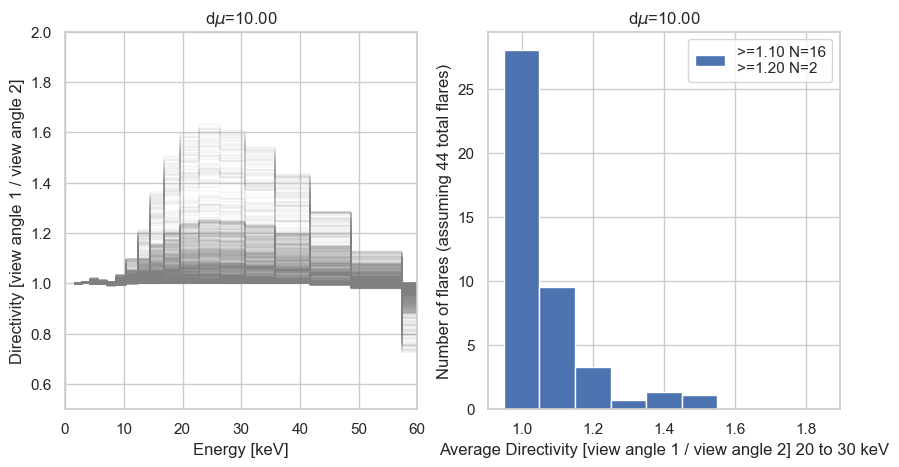

In [65]:
avg_ani = plot_anisotropy_flares(anisotropy_index=2, no_flares=44, m=1000)

In [66]:
44*np.sum(np.array(avg_ani)>1.2)/len(avg_ani)

6.424